# v2 · RSNA Pneumonia — детектор YOLO26l, пороги цепочки и тест Kaggle

- классификатор **ConvNeXt V2 Base** с аугментациями, детектор **YOLO26l**;
- снимки **640×640** для обеих моделей;
- деление **train / val = 80 / 20**, итоговый тест — закрытый тест Kaggle.

| Версия | t2 | conf | цепочка, val | Kaggle Private | Kaggle Public |
|---|---|---|---|---|---|
| v1: Tiny + YOLO26m, 512, без аугментаций | 0.50 | 0.25 | 0.221 | 0.121 | 0.048 |
| v2: Base + YOLO26l, 640, ранняя остановка YOLO на 24-й эпохе | 0.25 | 0.25 | 0.174 | 0.083 | 0.024 |
| **v2.1: то же, YOLO26l все 50 эпох (этот ноутбук)** | 0.25 | 0.25 | 0.211 | **0.119** | 0.042 |

YOLO26l v2.1 на val: mAP50 0.532, mAP50-95 0.205.

**Вывод:** в первой попытке YOLO26l остановился на высоком lr и недоучился. С полным расписанием он догнал v1, но крупные модели, 640 и аугментации в сумме прироста не дали.

> Ноутбук использует `meta`, `boxes_640` и `val_probs` из ноутбука классификатора v2.

## 0. Установка и подключение Google Drive

In [1]:
!pip install -q pydicom pylibjpeg pylibjpeg-libjpeg ultralytics timm

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


## 1. Пути и константы

Всё, что меняется от эксперимента к эксперименту, — в этой ячейке.

In [3]:
from pathlib import Path

project = Path("/content/drive/MyDrive/rsna_project_final")

META = project / "meta_classifier_ConvNeXt_V2_Base_with_aug.csv"
BOXES = project / "boxes_640_classifier_ConvNeXt_V2_Base_with_aug.csv"

CLS_NAME = "convnextv2_base.fcmae_ft_in22k_in1k_384"
CLS_DIR = project / "classifier_ConvNeXt_V2_Base_with_aug"
CLS_WEIGHTS = CLS_DIR / "classifier_best_for_f1_ConvNeXt_V2_Base_with_aug.pt"
VAL_PROBS = CLS_DIR / "val_probs_ConvNeXt_V2_Base_with_aug.csv"

YOLO_MODEL = "yolo26l.pt"
YOLO_RUN = "split_v2_yolo26l_2"

SIZE = 640
SEED = 42
MEAN, STD = 0.449, 0.226

## 2. Данные

Архив, `meta` с делением train / val и боксы в масштабе 640.

In [4]:
import zipfile
import pandas as pd

zip_path = Path("/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip")
extract_dir = Path("/content/extract_dir")
if not (extract_dir / ".done").exists():
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_dir)
    (extract_dir / ".done").touch()
train_image_path = extract_dir / "stage_2_train_images"

meta = pd.read_csv(META)
boxes = pd.read_csv(BOXES)
print(meta["split"].value_counts())

split
train    21347
val       5337
Name: count, dtype: int64


## 3. Препроцессинг

Те же функции, что в ноутбуке классификатора, без изменений — обе модели должны видеть одинаковые снимки.

In [5]:
import sys
import numpy as np
import cv2
import pydicom

def percentile_clip(data, lower_percentile=0.5, upper_percentile=99.5):
    low_val, high_val = np.percentile(data, [lower_percentile, upper_percentile])
    return np.clip(data, low_val, high_val)

def read_dicom(dicom_path):
    dcm = pydicom.dcmread(dicom_path)
    img = dcm.pixel_array.astype("float32")
    if dcm.PhotometricInterpretation == "MONOCHROME1":
        img = img.max() - img
    img = percentile_clip(img)
    img = (img - np.min(img)) / (np.max(img) - np.min(img) + sys.float_info.epsilon)
    return np.round(img * 255).astype(np.uint8)

def resize_img(img, size=SIZE):
    resized_img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return resized_img, resized_img.shape[0] / img.shape[0]

## 4. Датасет YOLO

- все снимки с пневмонией;
- фон — снимки классов 0 и 1 с пустым `.txt`, 25% от числа больных. Без фона YOLO привыкает, что очаг есть всегда.

In [6]:
sick = meta[meta["label"] == 2]                            # все снимки с боксами
background = []
for split in ["train", "val"]:
    n = int(len(sick[sick["split"] == split]) * 0.25)      # фона — 25% от числа больных
    healthy = meta[(meta["label"] != 2) & (meta["split"] == split)]
    background.append(healthy.sample(n, random_state=SEED))

yolo_df = pd.concat([sick] + background)
print(pd.crosstab(yolo_df["split"], yolo_df["label"]))

label    0    1     2
split                
train  536  666  4809
val    140  160  1203


Один проход: PNG 640 и `.txt` в формате YOLO `0 cx cy w h`, центр и размер в долях от 640.

In [7]:
from tqdm import tqdm

root = Path("/content/dataset")
for split in ["train", "val"]:
    (root / split / "images").mkdir(parents=True, exist_ok=True)
    (root / split / "labels").mkdir(parents=True, exist_ok=True)

for pid, split in tqdm(zip(yolo_df["patientId"], yolo_df["split"]), total=len(yolo_df)):
    # снимок
    img, _ = resize_img(read_dicom(train_image_path / f"{pid}.dcm"), SIZE)
    cv2.imwrite(str(root / split / "images" / f"{pid}.png"), img)

    # разметка: центр и размер в долях от SIZE; у фона файл пустой
    lines = []
    for b in boxes[boxes["patientId"] == pid].itertuples():
        cx = (b.x + b.width / 2) / SIZE
        cy = (b.y + b.height / 2) / SIZE
        lines.append(f"0 {cx:.6f} {cy:.6f} {b.width / SIZE:.6f} {b.height / SIZE:.6f}")
    (root / split / "labels" / f"{pid}.txt").write_text("\n".join(lines))

(root / "data.yaml").write_text("path: /content/dataset\ntrain: train/images\nval: val/images\nnc: 1\nnames: ['opacity']\n")

100%|██████████| 7514/7514 [06:43<00:00, 18.60it/s]


84

In [8]:
for split in ["train", "val"]:
    n_img = len(list((root / split / "images").glob("*.png")))
    n_txt = len(list((root / split / "labels").glob("*.txt")))
    print(split, n_img, "png |", n_txt, "txt")

train 6011 png | 6011 txt
val 1503 png | 1503 txt


## 5. Обучение YOLO26l

Цветовые аугментации (`hsv_*`) выключены: на сером рентгене они бессмысленны. Масштабирование уменьшено до 0.2. Батч 32: модель l на 640 тяжелее, 64 может не поместиться в память.

In [9]:
from ultralytics import YOLO

model = YOLO(YOLO_MODEL)
results = model.train(
    data="/content/dataset/data.yaml",
    imgsz=SIZE,
    epochs=50,
    patience=0,
    batch=32,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    fliplr=0.5,
    scale=0.2,
    cache="ram",
    seed=SEED,
    project=str(project / "yolo"),
    name=YOLO_RUN,
)
run = Path(results.save_dir)
print(run)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fracti

### Кривые обучения, PR-кривая, матрица ошибок

Если среда перезапускалась после обучения, задай путь вручную: `run = project / "yolo" / YOLO_RUN`.

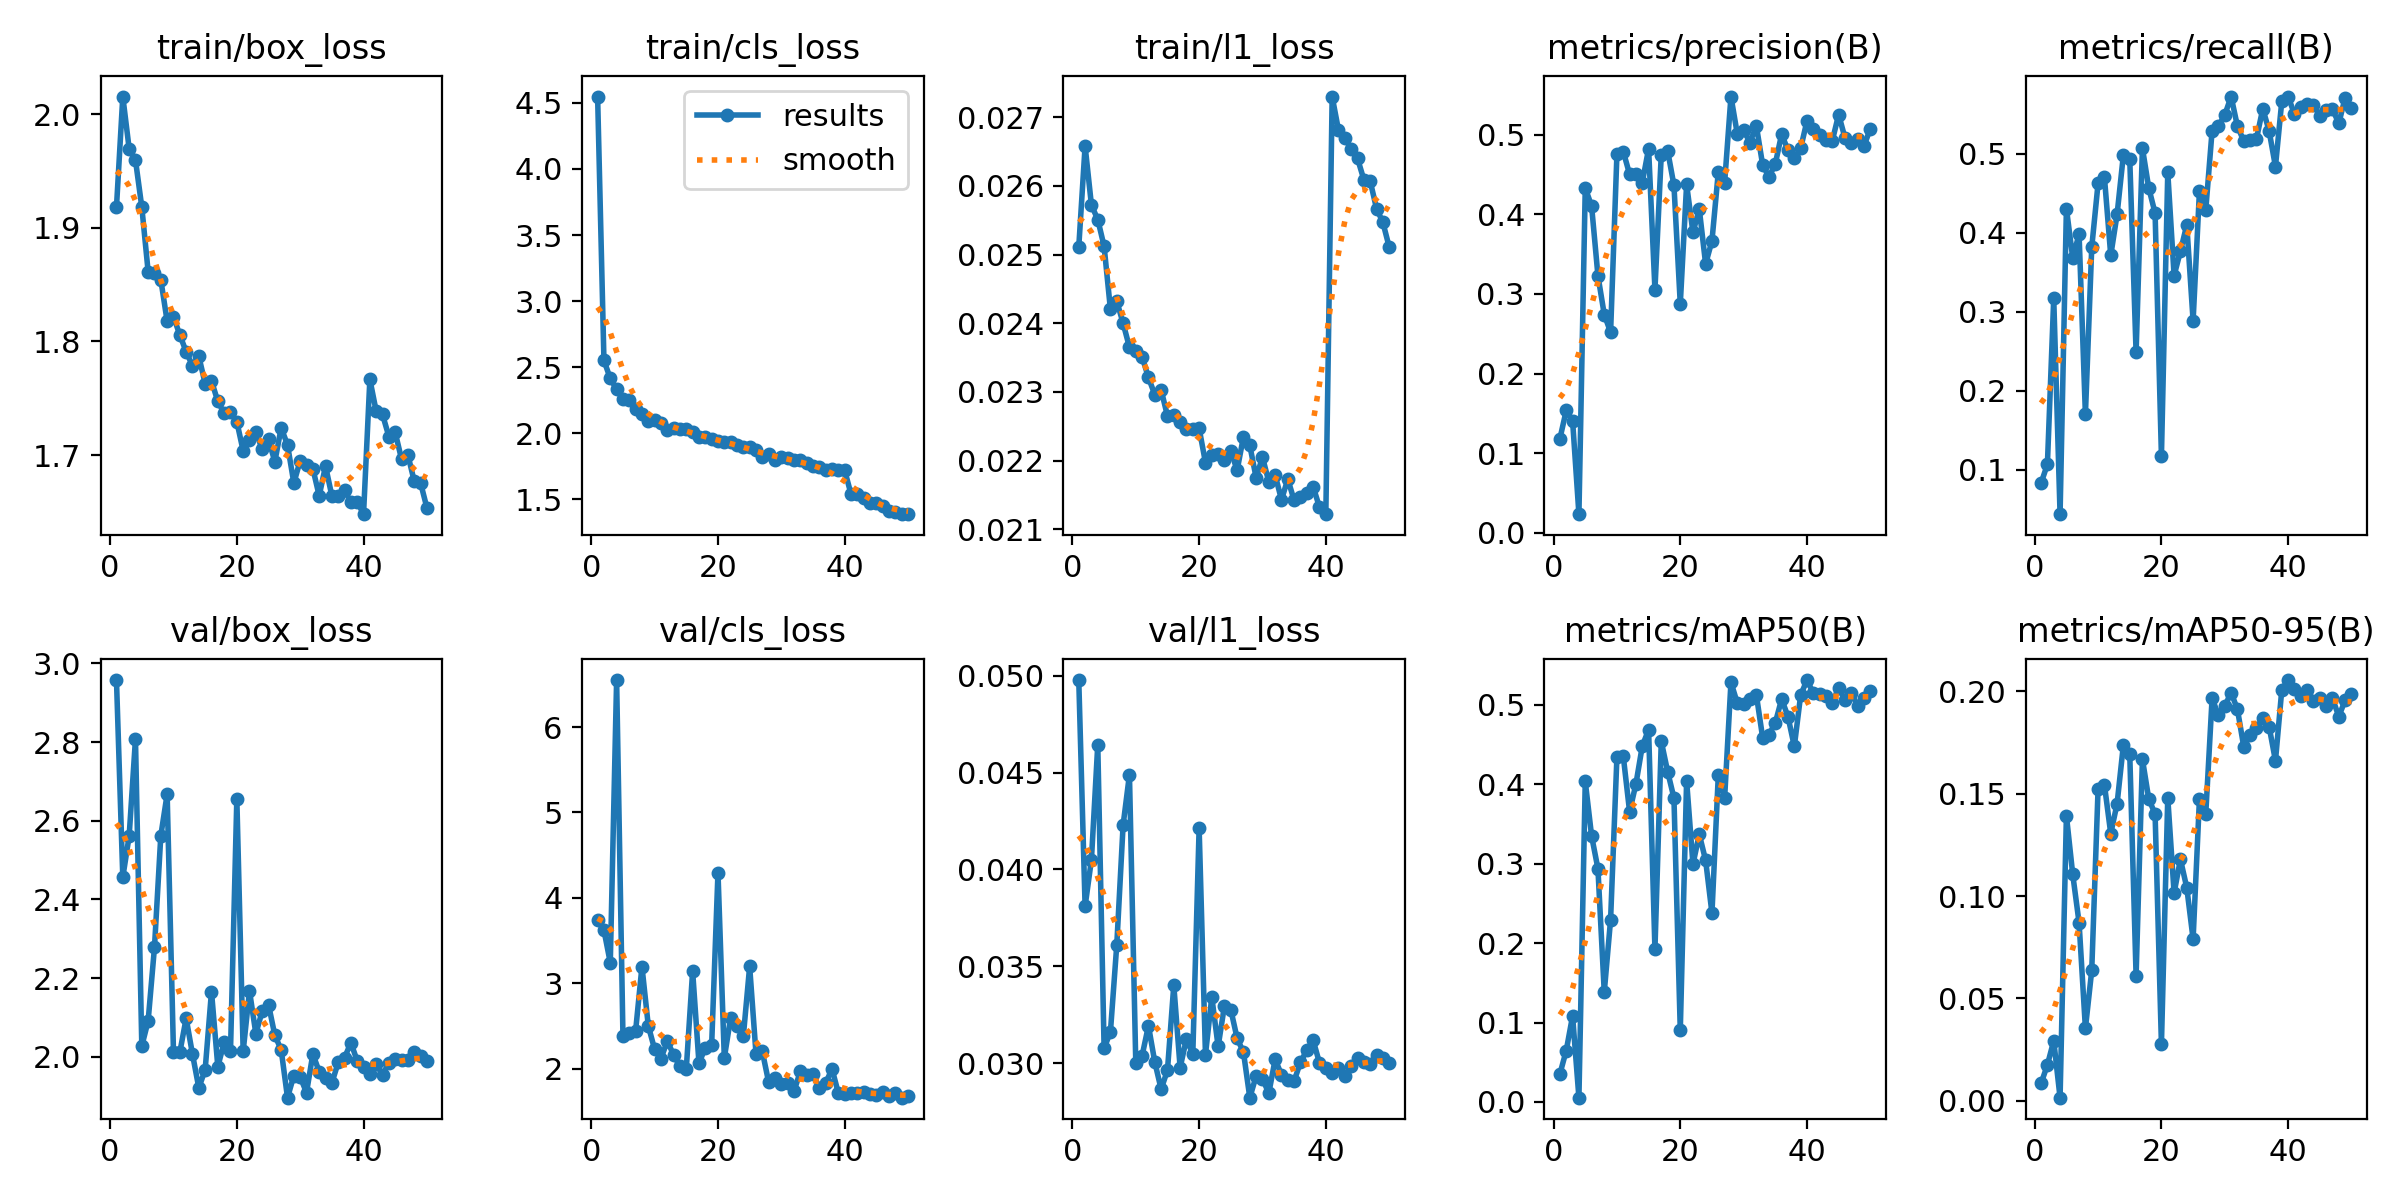

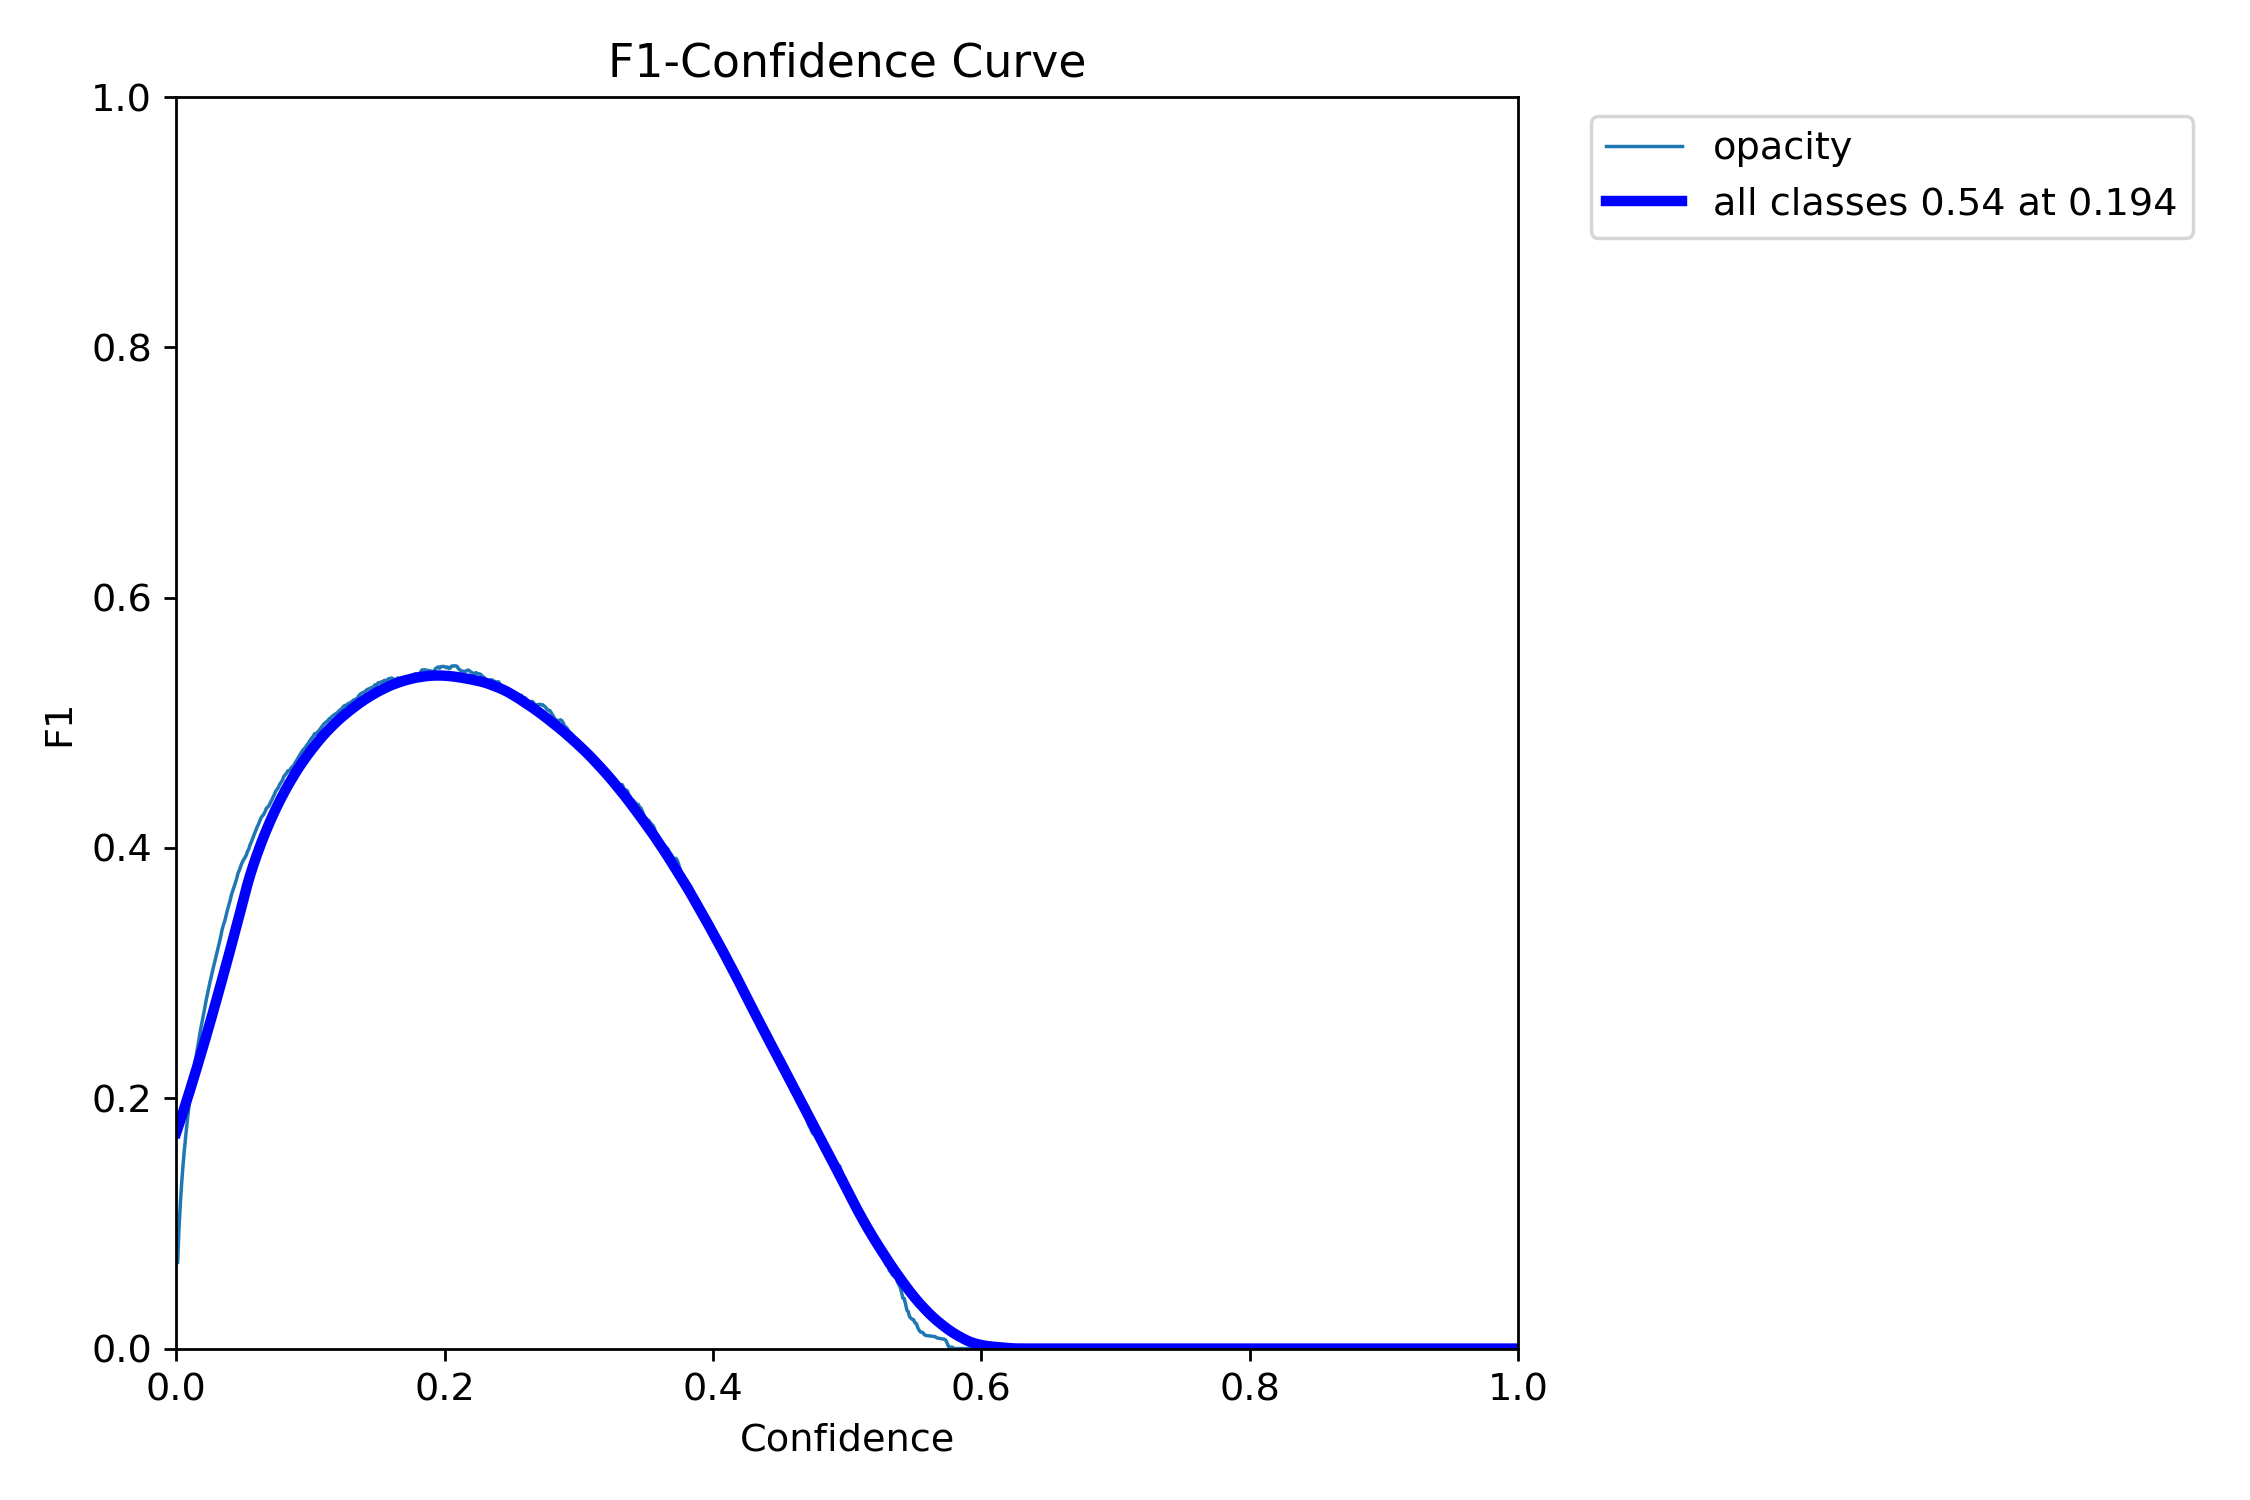

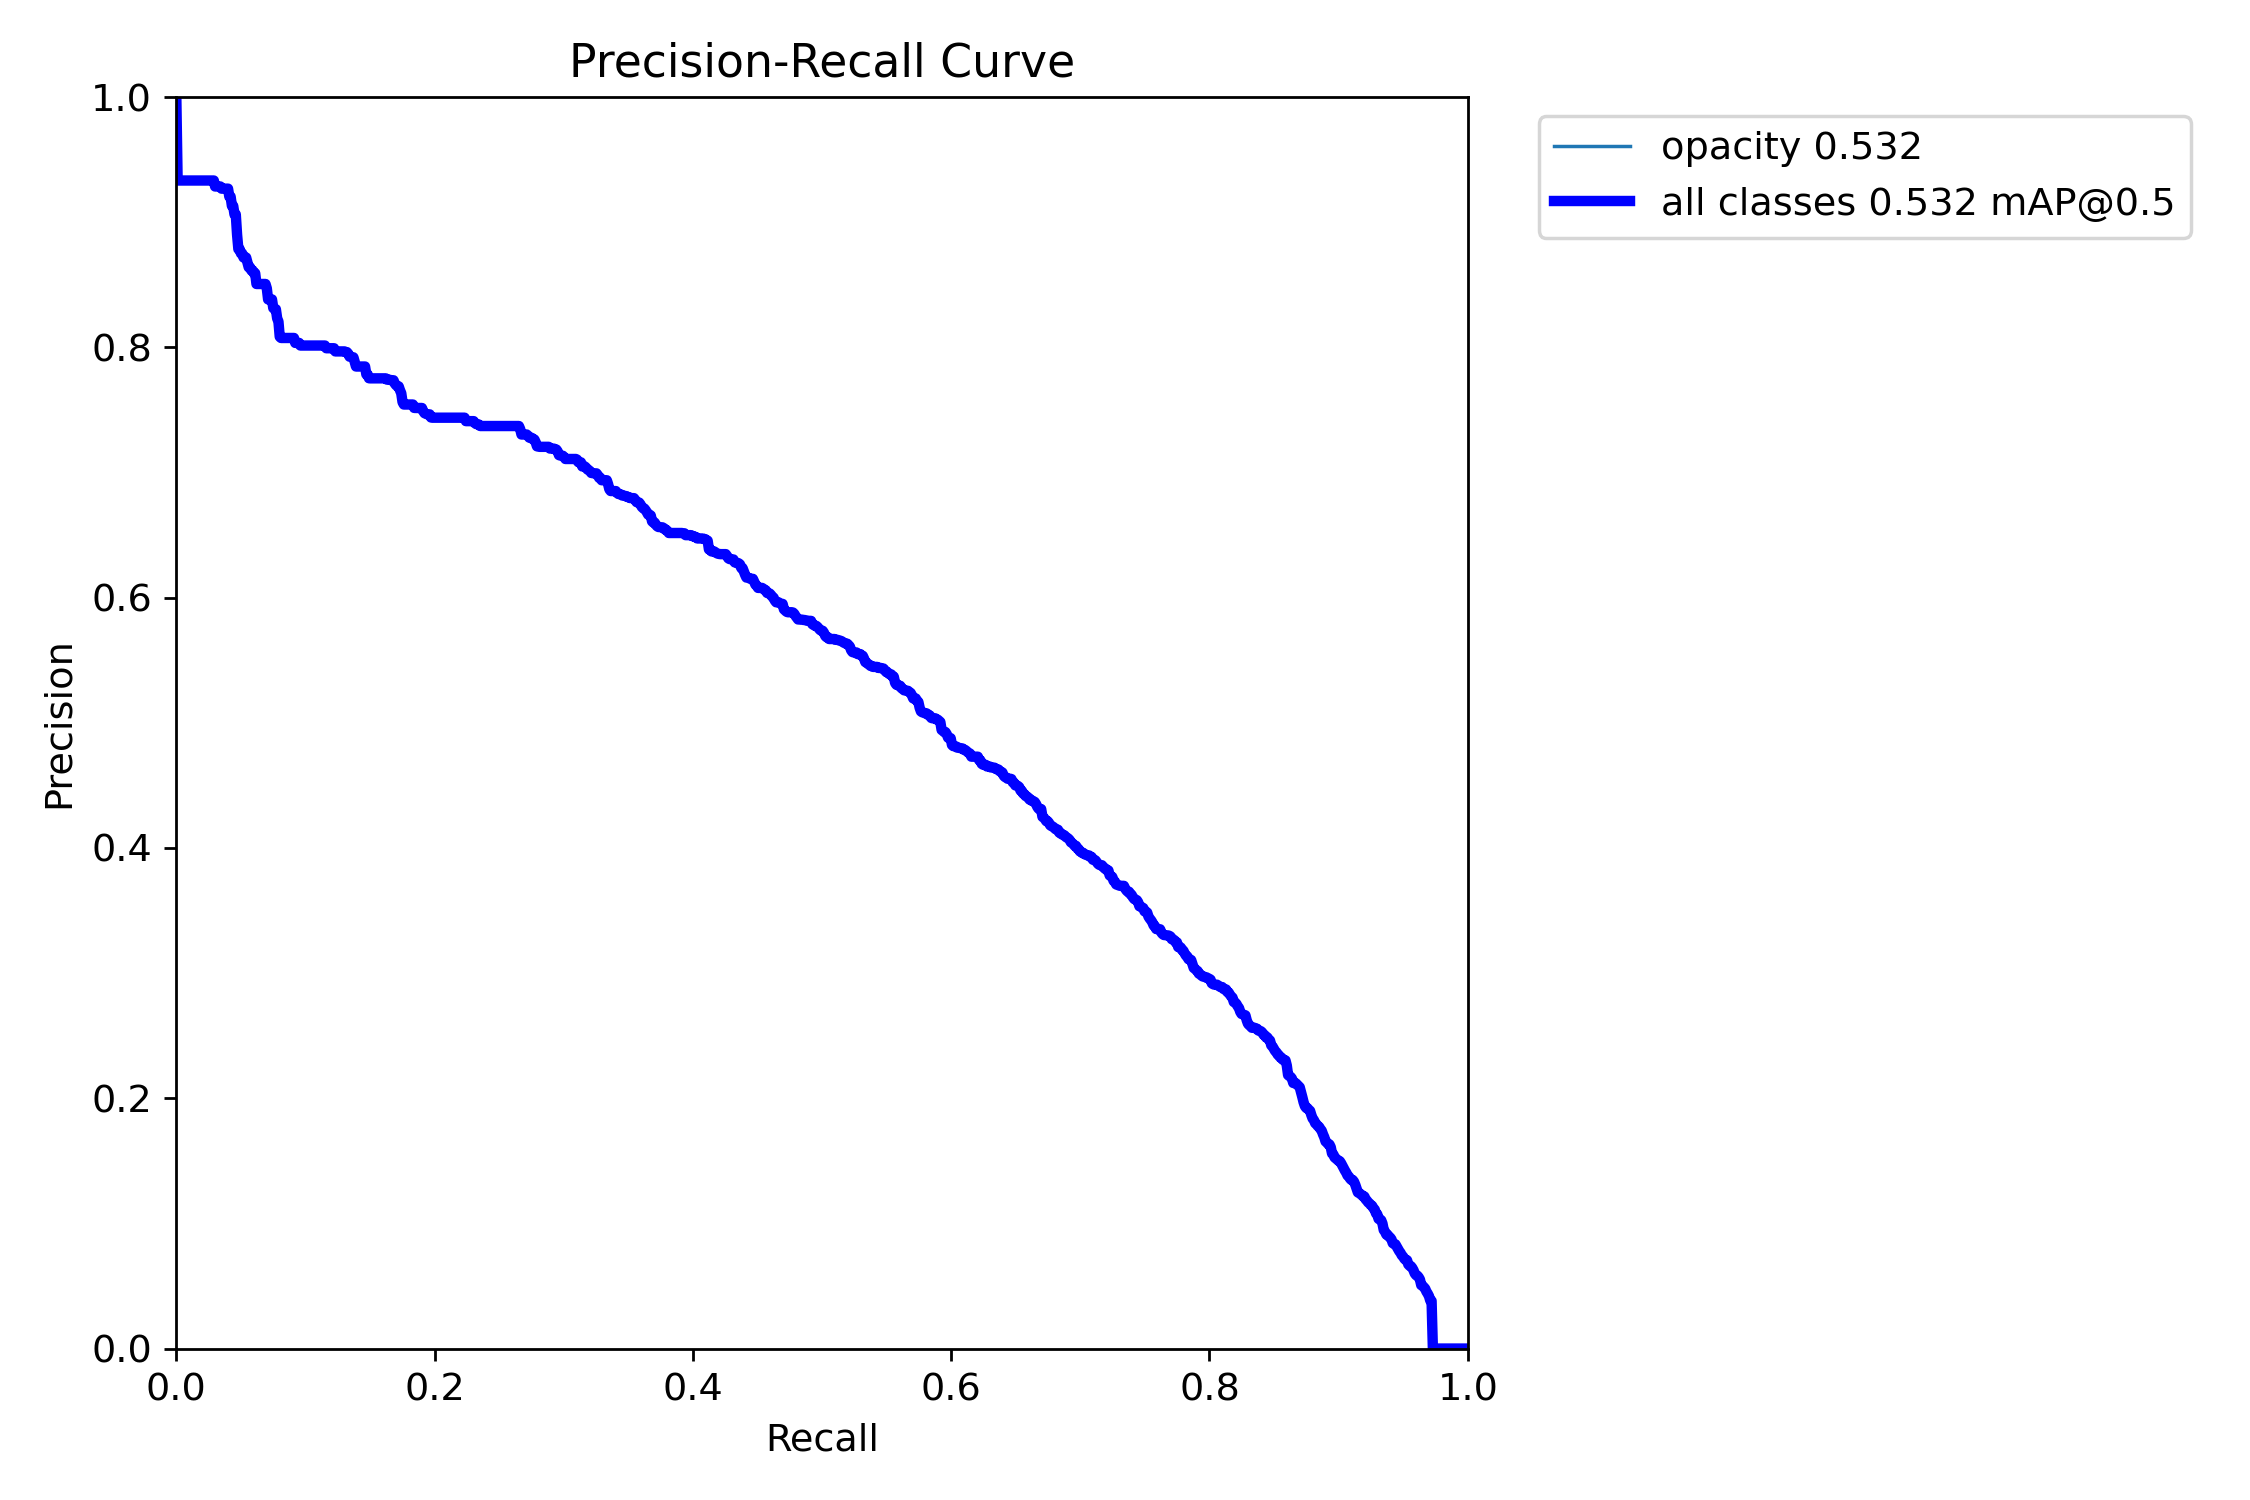

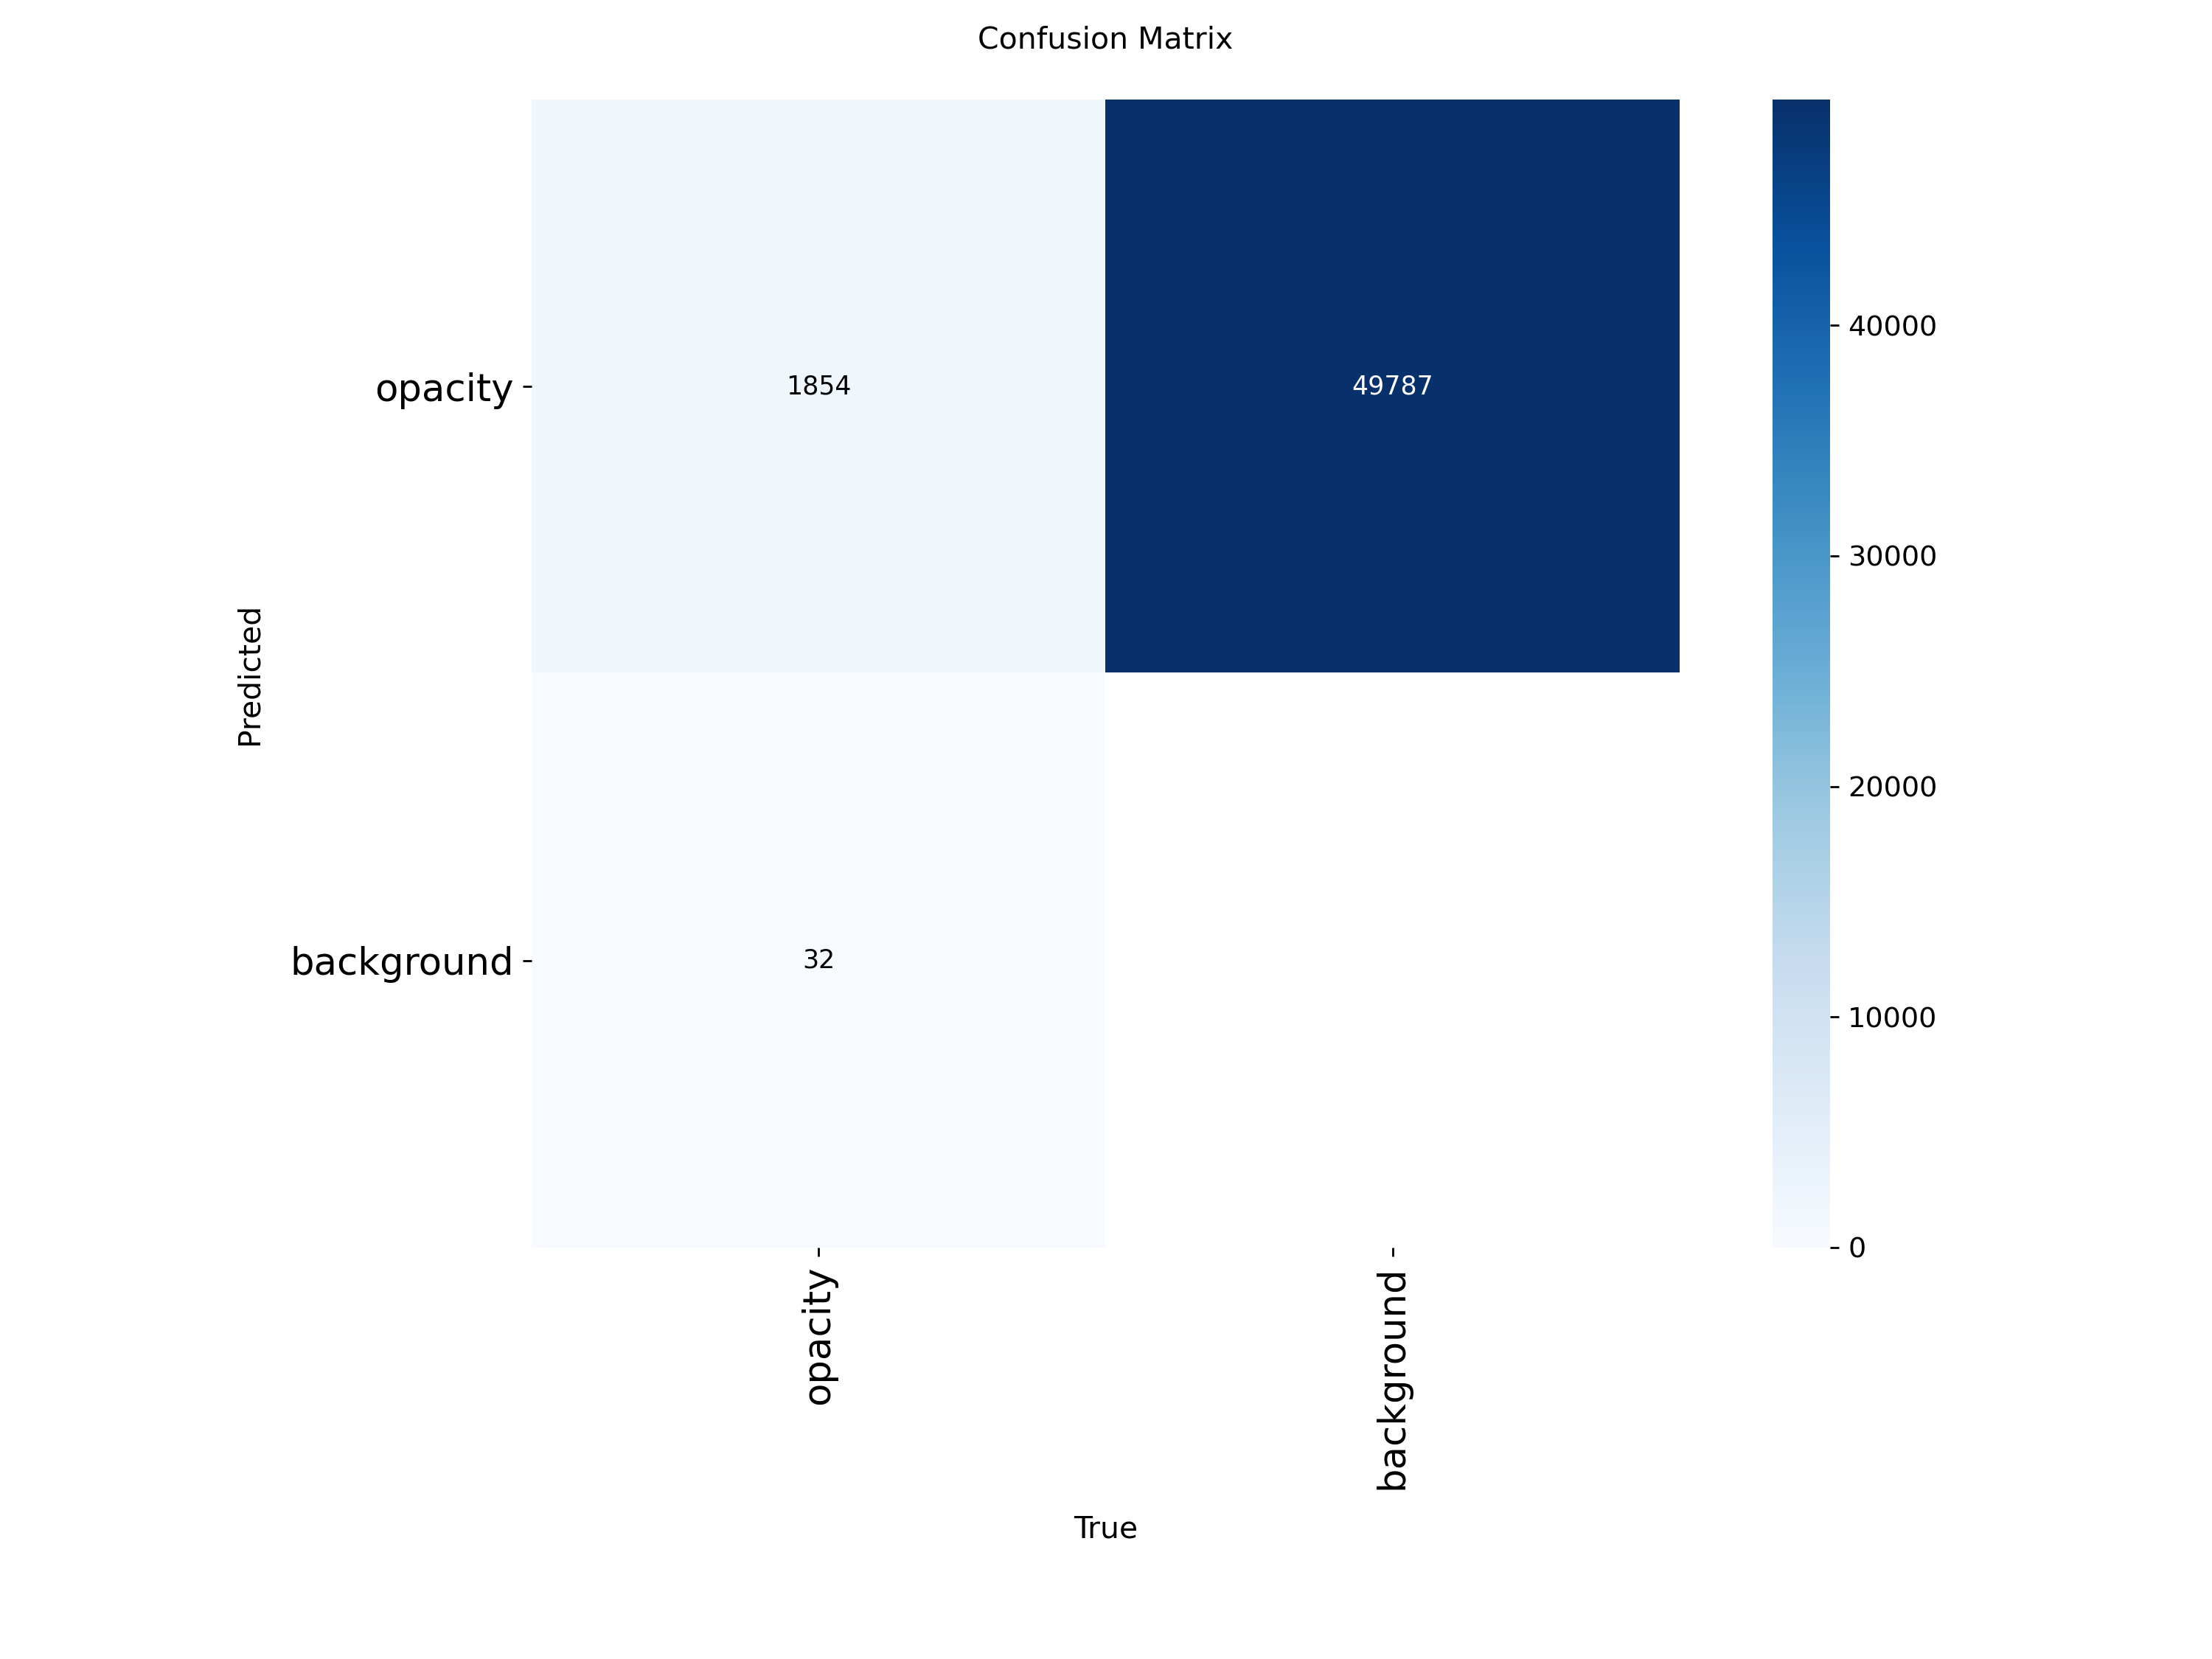

In [10]:
from IPython.display import Image, display

for name in ["results.png", "BoxF1_curve.png", "BoxPR_curve.png", "confusion_matrix.png"]:
    p = run / name
    if p.exists():
        display(Image(filename=str(p), width=900))
    else:
        print("нет файла:", name)

### Предсказания глазами
Зелёные рамки — разметка, красные — предсказания YOLO с уверенностью.

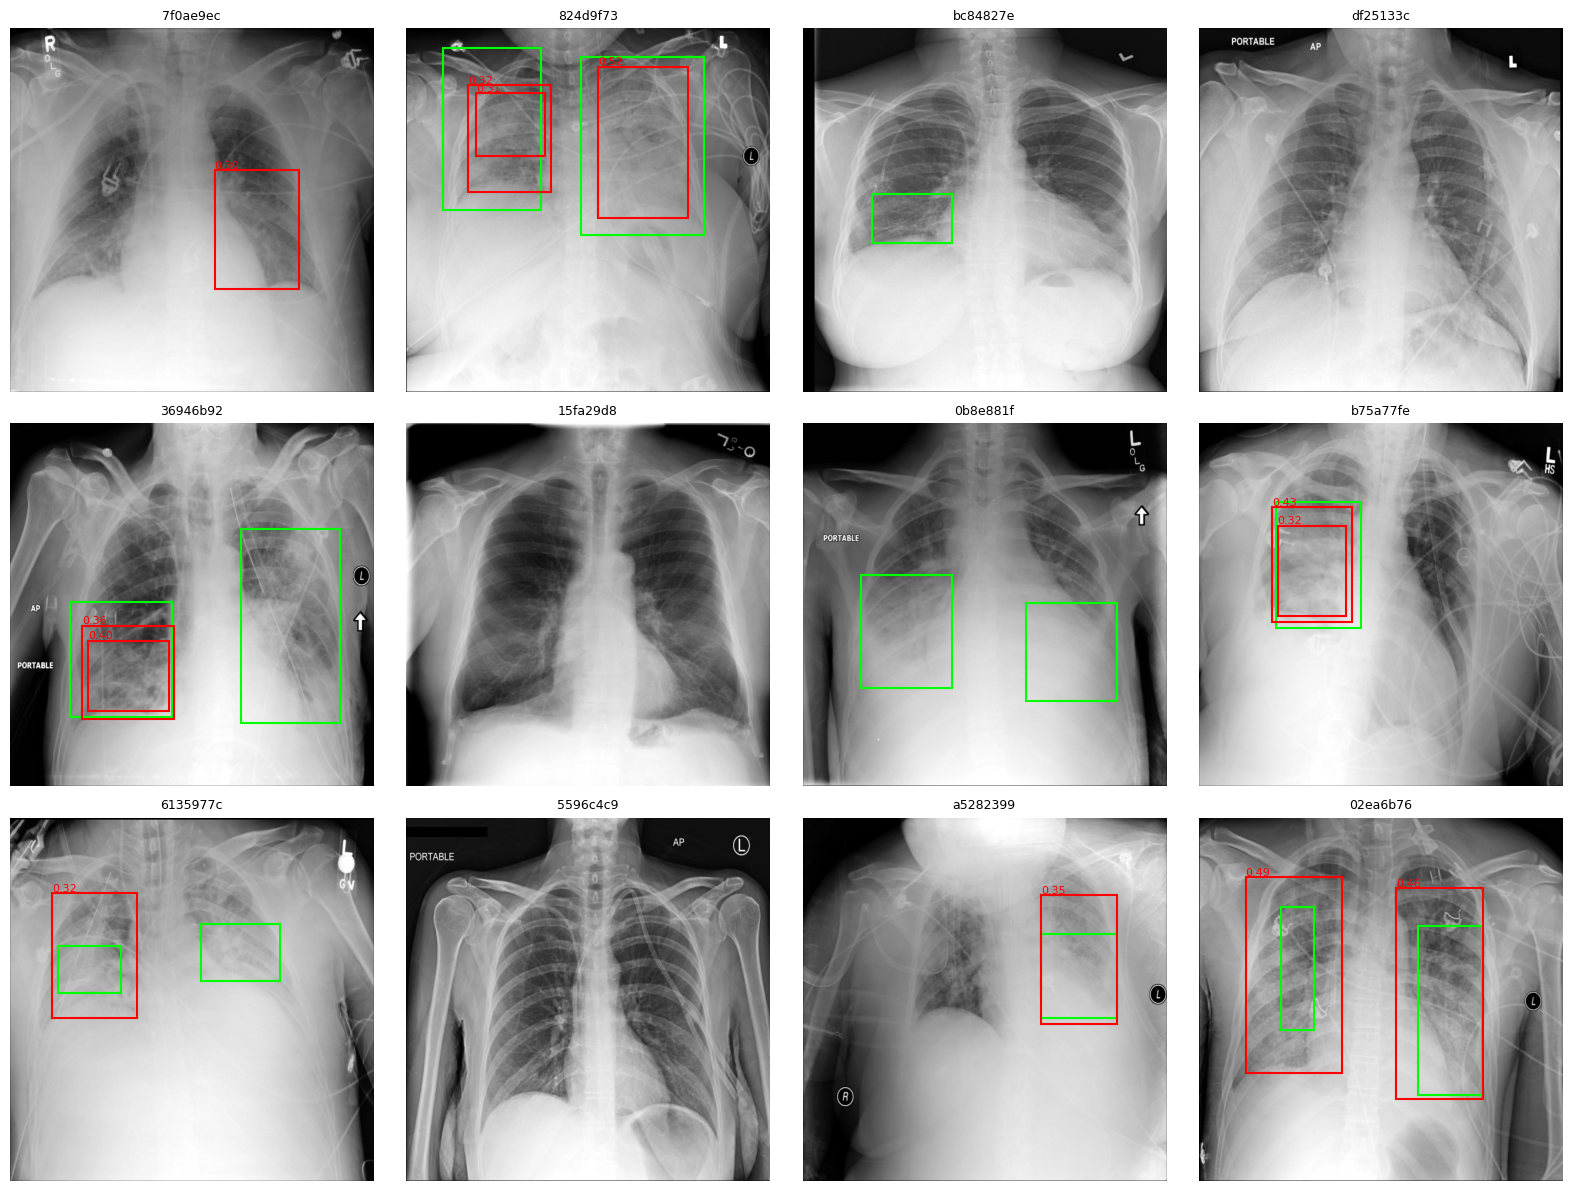

In [11]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ultralytics import YOLO
model = YOLO(run / "weights" / "best.pt")

def show_preds(img_dir, lab_dir, n=12, seed=0, conf=0.25, cols=4):
    paths = sorted(img_dir.glob("*.png"))
    random.Random(seed).shuffle(paths)
    paths = paths[:n]
    results = model.predict([str(p) for p in paths], imgsz=SIZE, conf=conf, verbose=False)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    for ax, p, r in zip(axes.flat, paths, results):
        ax.imshow(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), cmap="gray")
        for line in (lab_dir / f"{p.stem}.txt").read_text().splitlines():      # настоящие
            _, cx, cy, w, h = map(float, line.split())
            ax.add_patch(patches.Rectangle(((cx - w / 2) * SIZE, (cy - h / 2) * SIZE),
                         w * SIZE, h * SIZE, fill=False, edgecolor="lime", linewidth=1.5))
        for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):  # предсказанные
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                         fill=False, edgecolor="red", linewidth=1.5))
            ax.text(x1, y1 - 3, f"{c:.2f}", color="red", fontsize=8)
        ax.set_title(p.stem[:8], fontsize=9)
        ax.axis("off")
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_preds(root / "val" / "images", root / "val" / "labels")

## 6. Метрика соревнования

Для каждого снимка при порогах IoU 0.40, 0.45 … 0.75 считается `TP / (TP + FP + FN)`, затем среднее по порогам и по снимкам.
- нет разметки и нет предсказаний → снимок не учитывается;
- нет разметки, но есть хоть один бокс → снимок получает 0.

In [12]:
THRESHOLDS = np.round(np.arange(0.4, 0.76, 0.05), 2)   # 0.4, 0.45, ..., 0.75

def iou_matrix(a, b):
    """IoU каждого бокса из a с каждым из b. Боксы — (n, 4): x, y, width, height."""
    ax1, ay1, ax2, ay2 = a[:, 0], a[:, 1], a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx1, by1, bx2, by2 = b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2) - np.maximum(ax1[:, None], bx1), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2) - np.maximum(ay1[:, None], by1), 0, None)
    inter = iw * ih
    union = (a[:, 2] * a[:, 3])[:, None] + b[:, 2] * b[:, 3] - inter
    return inter / union


def image_ap(gt, pred, scores):
    """AP одного снимка по правилам Kaggle. None — снимок не учитывается."""
    if len(gt) == 0 and len(pred) == 0:
        return None
    if len(gt) == 0 or len(pred) == 0:
        return 0.0
    pred = pred[np.argsort(-scores)] # сначала самые уверенные
    ious = iou_matrix(pred, gt) # (число предсказаний, число настоящих)
    aps = []
    for t in THRESHOLDS:
        matched, tp = set(), 0
        for i in range(len(pred)):
            cand = [j for j in range(len(gt)) if j not in matched and ious[i, j] > t]
            if cand: # совпал с ещё не занятым настоящим боксом
                matched.add(max(cand, key=lambda j: ious[i, j]))
                tp += 1
        fp, fn = len(pred) - tp, len(gt) - tp
        aps.append(tp / (tp + fp + fn))
    return float(np.mean(aps))

## 7. Подбор порогов цепочки на val

YOLO один раз проходит по всем снимкам val (порог 0.01), дальше перебираются пары `t2 × conf` без повторных прогонов. `t2 = 0` — вариант «только YOLO».

In [13]:
val = pd.read_csv(VAL_PROBS)
gt_boxes = {pid: g[["x", "y", "width", "height"]].to_numpy() for pid, g in boxes.groupby("patientId")}
yolo = YOLO(str(run / "weights" / "best.pt"))

# --- YOLO на каждом снимке val один раз ---
def yolo_all(ids):
    out = {}
    for pid in tqdm(ids):
        img, _ = resize_img(read_dicom(train_image_path / f"{pid}.dcm"), SIZE)
        r = yolo.predict(np.repeat(img[..., None], 3, axis=2), imgsz=SIZE, conf=0.01, verbose=False)[0]
        xyxy = r.boxes.xyxy.cpu().numpy()
        out[pid] = (np.c_[xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]], r.boxes.conf.cpu().numpy())
    return out

val_yolo = yolo_all(val["patientId"])

# --- метрика цепочки при двух порогах ---
def chain_score(df, yolo_out, t2, conf):
    aps = []
    for pid, p2 in zip(df["patientId"], df["prob2"]):
        pred, scores = yolo_out[pid]
        keep = (scores >= conf) & (p2 >= t2)          # гейт классификатора + порог YOLO
        ap = image_ap(gt_boxes.get(pid, np.zeros((0, 4))), pred[keep], scores[keep])
        if ap is not None:
            aps.append(ap)
    return np.mean(aps)

# --- перебор на val ---
score_val, t2, conf = max((chain_score(val, val_yolo, t, c), t, c)
                          for t in np.arange(0, 0.81, 0.05) for c in np.arange(0.05, 0.81, 0.05))
score_only_yolo = max(chain_score(val, val_yolo, 0, c) for c in np.arange(0.05, 0.81, 0.05))
print(f"лучшие пороги: prob2 >= {t2:.2f}, conf >= {conf:.2f} | val {score_val:.4f}")
print(f"только YOLO, лучший conf:          val {score_only_yolo:.4f}")

100%|██████████| 5337/5337 [05:45<00:00, 15.47it/s]


лучшие пороги: prob2 >= 0.25, conf >= 0.25 | val 0.2110
только YOLO, лучший conf:          val 0.1979


## 8. Отправка на Kaggle

Цепочка на 3 000 снимках закрытого теста. Боксы возвращаются из 640 в исходные 1024. Файл загружается через Late Submission.

In [14]:
import timm, torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
cls = timm.create_model(CLS_NAME, pretrained=False, num_classes=3, in_chans=1)
cls.load_state_dict(torch.load(CLS_WEIGHTS, map_location=DEVICE))
cls = cls.to(DEVICE).eval()

rows = []
for path in tqdm(sorted((extract_dir / "stage_2_test_images").glob("*.dcm"))):
    img, scale = resize_img(read_dicom(path), SIZE)

    x = torch.from_numpy(img).float().div(255)[None, None]
    with torch.no_grad():
        p2 = torch.softmax(cls(((x - MEAN) / STD).to(DEVICE)), dim=1)[0, 2].item()

    pred = ""
    if p2 >= t2:                                     # гейт классификатора
        r = yolo.predict(np.repeat(img[..., None], 3, axis=2), imgsz=SIZE, conf=conf, verbose=False)[0]
        for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy() / scale, r.boxes.conf.cpu().numpy()):
            pred += f"{c:.3f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f} "
    rows.append(dict(patientId=path.stem, PredictionString=pred.strip()))

sub = pd.DataFrame(rows)
sub.to_csv(project / "submission_ConvNeXt_V2_Base_aug_YOLO26l_640_2.csv", index=False)
print("снимков с боксами:", (sub["PredictionString"] != "").sum(), "из", len(sub))

100%|██████████| 3000/3000 [04:08<00:00, 12.06it/s]


снимков с боксами: 700 из 3000


## Итог

Цепочка на val — 0.211 (только YOLO — 0.198), Kaggle Private — **0.119**, Public — 0.042. Боксы на 700 из 3000 тестовых снимков.